# RBIG Demo

In [39]:
!pip install python-picard
!pip install "git+https://github.com/IPL-UV/rbig.git"

import numpy as np
import warnings
from time import time

# from rbig.model import RBIG
from sklearn.model_selection import train_test_split
from sklearn.utils import check_random_state
import matplotlib.pyplot as plt
plt.style.use('ggplot')
warnings.filterwarnings('ignore') # get rid of annoying warnings

%matplotlib inline
%load_ext autoreload
%autoreload 2

  Cloning https://github.com/IPL-UV/rbig.git to /tmp/pip-req-build-96zh_4mk
  Running command git clone -q https://github.com/IPL-UV/rbig.git /tmp/pip-req-build-96zh_4mk
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### Penguins Data

In [40]:
import seaborn as sns
penguins = sns.load_dataset("penguins")

In [41]:
penguins.dropna(inplace = True)

In [42]:
data = penguins.values[:,2:6]

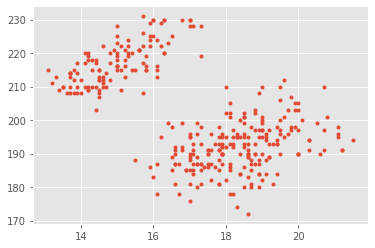

In [43]:
plt.plot(data[:,1],data[:,2],'.')

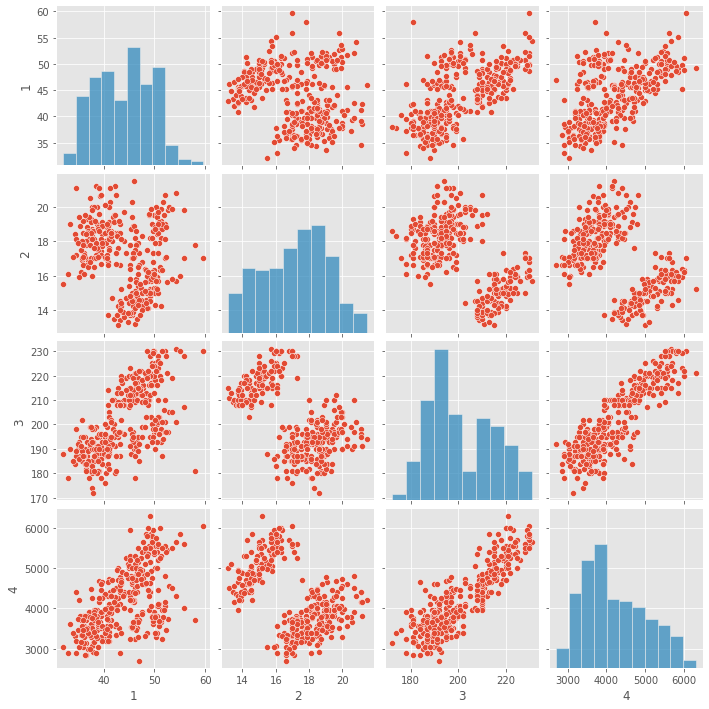

In [45]:
import pandas as pd
data_pd = pd.DataFrame(data,columns=['1','2','3','4'])
sns.pairplot(data_pd)

In [46]:
data.shape

(333, 4)

In [47]:
data = data.astype(np.float)

## RBIG Fitting

In [48]:
from rbig import RBIG

In [63]:
# Initialize RBIG class
rot = 'ica' # 'random','pca', 'ica'

rbig_model = RBIG(bound_ext = 0.01, rotation=rot)

# transform data
data_trans = rbig_model.fit_transform(data)

Completed! (Total Info Red: 0.8318):   6%|▋         | 64/1000 [00:03<00:52, 17.93it/s]


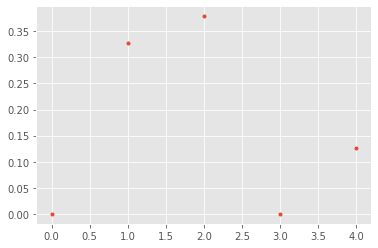

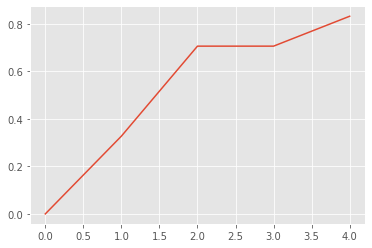

In [64]:
plt.figure()
plt.plot(rbig_model.info_loss,'.')
plt.figure()
plt.plot(np.cumsum(rbig_model.info_loss))

### Transform Data into Gaussian

(333, 4)


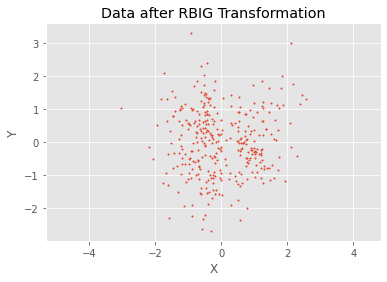

In [65]:
print(data_trans.shape)
fig, ax = plt.subplots()
ax.scatter(data_trans[:, 0], data_trans[:, 1], s=2)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Data after RBIG Transformation')
ax.axis('equal')
plt.show()

### Invertible

In [66]:
%%time
# transform data
data_approx = rbig_model.inverse_transform(data_trans)

# check approximation
np.testing.assert_array_almost_equal(data, data_approx)

CPU times: user 6.56 ms, sys: 40 µs, total: 6.6 ms
Wall time: 6.63 ms


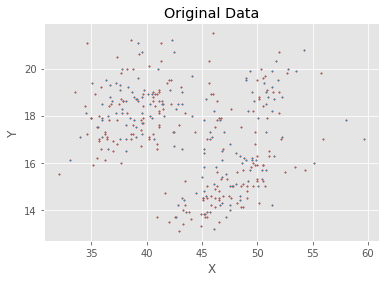

In [67]:
fig, ax = plt.subplots()
ax.scatter(data[:, 0], data[:, 1], s=2)
ax.scatter(data_approx[:, 0], data_approx[:, 1], s=1)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Original Data')
plt.show()

In [68]:
np.sum(np.abs(data- data_approx))

3.170068652025293e-10

### Information Reduction

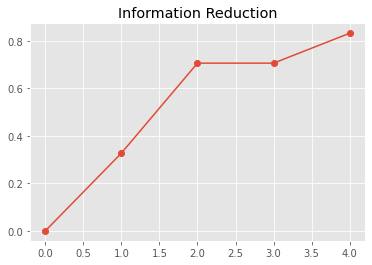

In [69]:

fig, ax = plt.subplots()
ax.plot(np.cumsum(rbig_model.info_loss),'o-')
ax.set_title('Information Reduction')
plt.show()

### Generated Synthetic Data

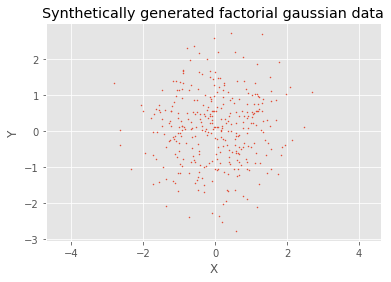

In [70]:
data_synthetic = np.random.randn(data.shape[0], data.shape[1])

fig, ax = plt.subplots()
ax.scatter(data_synthetic[:, 0], data_synthetic[:, 1], s=1)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Synthetically generated factorial gaussian data')
ax.axis('equal')
plt.show()

### Synthesize New Data from RBIG Model

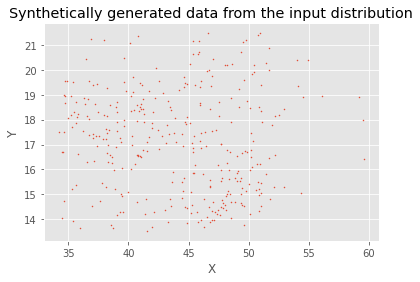

In [71]:
data_original_synthetic = rbig_model.inverse_transform(data_synthetic)

fig, ax = plt.subplots()
ax.scatter(data_original_synthetic[:, 0], data_original_synthetic[:, 1], s=1)
# ax.scatter(data[:, 0], data[:, 1], s=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Synthetically generated data from the input distribution')
plt.show()

In [72]:
import pandas as pd
data_synth_pd = pd.DataFrame(data_original_synthetic,columns=['1','2','3','4'])

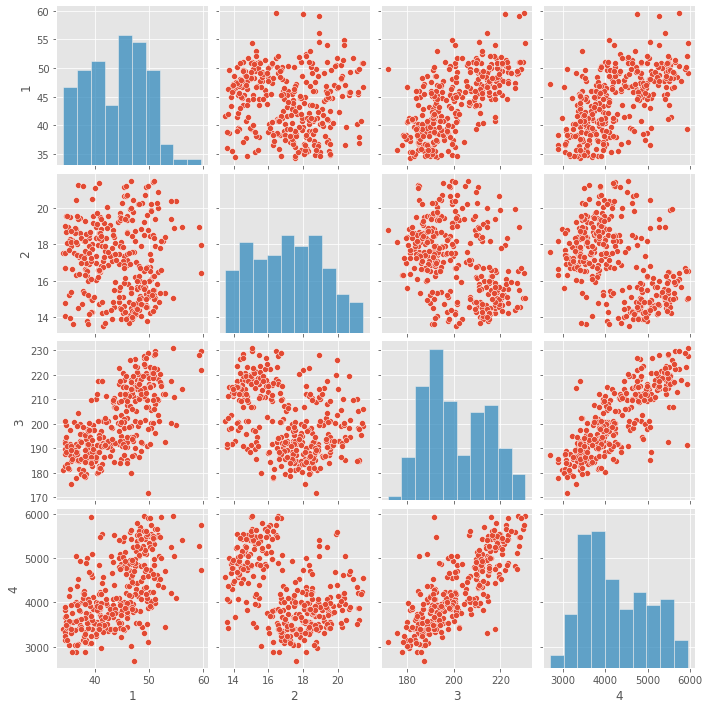

In [73]:
sns.pairplot(data_synth_pd)

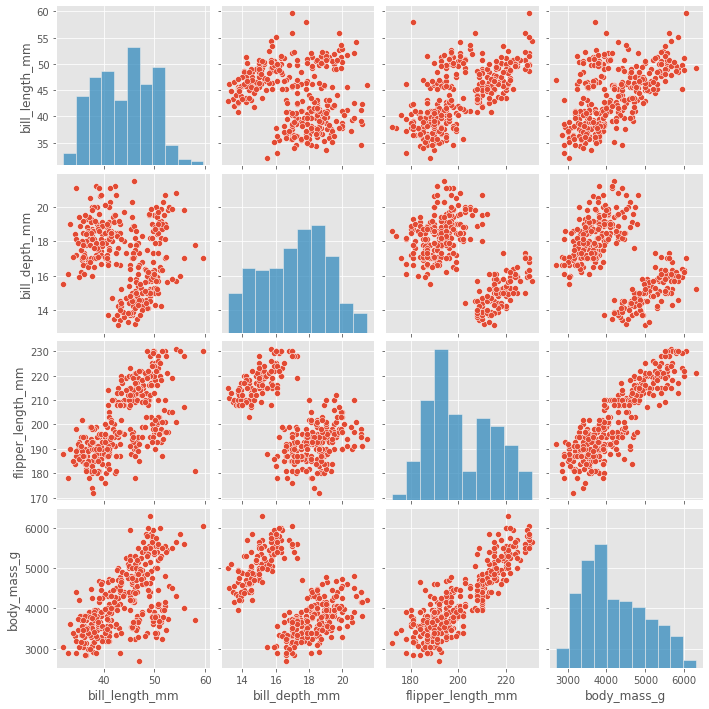

In [62]:
sns.pairplot(penguins)

### Estimating Probabilities with RBIG

In [ ]:
%%time
prob_input = rbig_model.predict_proba(data)

#print(f"Prob Input Domain - min: {prob_input.min():.3e}, max: {prob_input.max():.3e}")
#print(f"Prob Gauss Domain - min: {prob_gauss.min():.3e}, max: {prob_gauss.max():.3e}")
#print(f"Det:: {rbig_model.det_jacobians:.3e}")

CPU times: user 280 ms, sys: 605 µs, total: 281 ms
Wall time: 281 ms


### Original Data with Probabilities

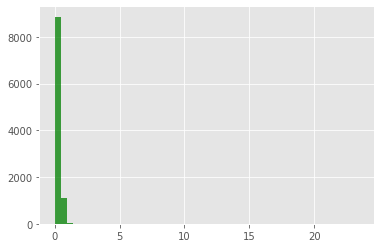

In [ ]:
fig, ax = plt.subplots()
ax.hist(np.log(prob_input+1), 50, facecolor='green', alpha=0.75)
plt.show()

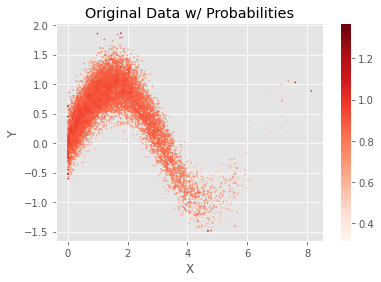

In [ ]:
fig, ax = plt.subplots()

h = ax.scatter(data[:, 0], data[:, 1], s=1, c=np.log(prob_input+1)**0.1, cmap='Reds')
#h = ax.scatter(data[:, 0], data[:, 1], s=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
cbar = plt.colorbar(h, )
ax.set_title('Original Data w/ Probabilities')
plt.show()